<a href="https://colab.research.google.com/github/navrajkambo/MLP_LSTM_XFMR-Policies-for-Robot-Imitation-Learning-on-PushT/blob/main/src/PushT_Imitation_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EECE568 - PushT Imitation Learning
### MLP, LSTM, and Transformer Policies

Organized like our assignments: shared imports and helper functions, followed by **Dataset and Dataloader**, **Network**, **Training**, and **Evaluation** subsections. All code is completed and runnable; the assignments were used only as a structural reference.

Run the cells from top to bottom. `INIT` prepares the same episode splits and normalization for all models; `P1`, `P2`, and `P3` train and evaluate MLP, LSTM, and Transformer respectively.  `COMP` compares the saved results. Choose a GPU in Colab for faster training.

### Project and Dataset Notes
This revision uses the official **`lerobot/pusht_keypoints` v3** dataset, pinned to a verified commit. It contains **206 episodes and 25,650 frames at 10 Hz**.

**Model input per frame:** concatenate `observation.state` (2D pusher position) with `observation.environment_state` (16 values representing eight 2D block keypoints) in that order. The resulting observation has **18 values**. Actions remain 2D pusher target positions. Rewards, success flags, episode IDs, frame IDs, and actions are not input features.

The linked [LeRobotDataset v3 documentation](https://huggingface.co/docs/lerobot/lerobot-dataset-v3) describes a storage format and reader, not a single fixed feature schema. The original `lerobot/pusht` dataset was already v3, but lacked the keypoint field. Switching readers cannot recover missing values; this notebook switches to the official keypoint variant instead.

This preserves the assignment structure and the proposal's MLP/LSTM/Transformer comparison, history lengths K in {1,2,4,8}, horizons H in {1,8}, train-only normalization, and episode-based five-fold design. Keypoints are supplied by the dataset; no image decoder, estimated block state, or fabricated features are used. The keypoint variant contains no videos.

Based on our EECE568 proposal. This notebook implements offline behavior cloning; simulator overlap/success and compounding-error experiments remain separate future work.

### Mount on Google Drive (Optional)
This is disabled by default so Run all works without a sign-in prompt. Set `USE_GOOGLE_DRIVE = True` to mount it; the settings cell below will save results to `MyDrive/EECE568_PushT/pusht_run`. Otherwise, results are saved in the current Colab session.

You can also run in colab by cloning the git repo directly (what Navraj is doing)

In [2]:
USE_GOOGLE_DRIVE = False
if USE_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')

### Install Dependencies

In [3]:
# Colab already provides a matched torch/torchvision pair; retain it.
%pip -q install "huggingface_hub>=0.34,<3" "pyarrow>=17,<26" "pandas>=2.2,<4" tqdm matplotlib

### Imports

In [4]:
import time
import numpy as np
import pandas as pd
import random
import matplotlib.pyplot as plt

# import standard PyTorch modules
import torch
import torch.nn as nn
import torch.optim as optim

# import torchvision module to handle image manipulation
import torchvision
import torchvision.transforms as transforms
print("Running on torch.__version__ = ", torch.__version__)

torch.backends.cudnn.deterministic = True

# utils
import os
from tqdm import tqdm
tqdm.pandas()
from collections import Counter

Running on torch.__version__ =  2.11.0+cu130


In [5]:
import json
import copy
import hashlib
import platform
from pathlib import Path
from IPython.display import display
from huggingface_hub import HfApi, hf_hub_download
from torch.utils.data import Dataset, DataLoader
import pyarrow.parquet as pq

### Helper Functions
These helpers are shared across the three models. They are defined here and called later, after the settings and datasets exist.

In [6]:
def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

In [7]:
def loss_parts(pred, target, mask):
    return (((pred-target)**2) * mask.unsqueeze(-1)).sum(), mask.sum()*target.shape[-1]

In [8]:
def run_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)
    numerator = denominator = 0.0
    with torch.set_grad_enabled(training):
        for x,y,mask,_ in loader:
            x,y,mask = x.to(DEVICE),y.to(DEVICE),mask.to(DEVICE)
            if training: optimizer.zero_grad(set_to_none=True)
            pred = model(x)
            s,n = loss_parts(pred,y,mask)
            loss = s/n
            assert torch.isfinite(loss), "Nonfinite loss"
            if training:
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(),1.0)
                optimizer.step()
            numerator += s.detach().item()
            denominator += n.detach().item()
    return numerator/denominator

In [9]:
@torch.no_grad()
def evaluate(model, loader):
    if model is not None: model.eval()
    ns = rs = denom = 0.0
    ep_totals = {}
    horizon_sums = np.zeros(H)
    horizon_counts = np.zeros(H)
    scale = torch.tensor(act_std,device=DEVICE)
    for x,y,mask,eps in loader:
        x,y,mask = x.to(DEVICE),y.to(DEVICE),mask.to(DEVICE)
        pred = torch.zeros_like(y) if model is None else model(x)
        normalized_sq = (pred-y)**2
        raw_sq = normalized_sq * scale.square()
        ns += (normalized_sq*mask.unsqueeze(-1)).sum().item()
        rs += (raw_sq*mask.unsqueeze(-1)).sum().item()
        denom += (mask.sum()*2).item()
        per_sample_sum = (raw_sq*mask.unsqueeze(-1)).sum((1,2)).cpu().numpy()
        per_sample_n = (mask.sum(1)*2).cpu().numpy()
        for ep,s,n in zip(eps.tolist(),per_sample_sum,per_sample_n):
            old = ep_totals.get(ep,(0.,0.))
            ep_totals[ep] = (old[0]+float(s),old[1]+float(n))
        horizon_sums += (raw_sq*mask.unsqueeze(-1)).sum((0,2)).cpu().numpy()
        horizon_counts += (mask.sum(0)*2).cpu().numpy()
    return {"normalized_mse": ns/denom, "raw_coordinate_mse": rs/denom,
            "episode_mean_raw_mse": np.mean([s/n for s,n in ep_totals.values()])}, np.divide(
                horizon_sums,horizon_counts,out=np.full(H,np.nan),where=horizon_counts>0)

In [10]:
def train_policy(name, cls):
    seed_everything(SEED)
    model = cls(K,H,DROPOUT,obs_dim=OBS_DIM).to(DEVICE)
    optimizer = optim.Adam(model.parameters(),lr=LR,weight_decay=WEIGHT_DECAY)
    train_loader = make_loader("train",shuffle=True)
    val_loader = make_loader("validation")
    best_loss, best_state, stale = float("inf"), None, 0
    rows = []
    started = time.time()
    for epoch in range(1,EPOCHS+1):
        train_loss = run_epoch(model,train_loader,optimizer)
        val_loss = run_epoch(model,val_loader)
        rows.append({"epoch": epoch, "train_mse": train_loss, "validation_mse": val_loss})
        print(f"{name} {epoch:02d}: train={train_loss:.5f}, validation={val_loss:.5f}")
        if val_loss < best_loss:
            best_loss, best_epoch = val_loss, epoch
            best_state = {key:value.detach().cpu().clone() for key,value in model.state_dict().items()}
            stale = 0
        else:
            stale += 1
        if stale >= PATIENCE: break
    assert best_state is not None
    model.load_state_dict(best_state)
    trained[name] = model.eval()
    histories[name] = pd.DataFrame(rows)
    tag = f"{name}_fold{FOLD}_seed{SEED}_k{K}_H{H}_drop{DROPOUT}"
    checkpoint_paths[name] = OUT / f"{tag}.pt"
    torch.save({"model_type": name, "model_state": best_state, "config": config,
                "normalization": {key:value.tolist() for key,value in norm.items()},
                "revision": REVISION, "split_manifest_sha256": split_hash,
                "episode_ids": {key:value.tolist() for key,value in split_ids.items()},
                "best_epoch": best_epoch, "best_validation_mse": best_loss,
                "versions": versions, "seconds": time.time()-started}, checkpoint_paths[name])
    histories[name].to_csv(OUT / f"{tag}_history.csv",index=False)
    return trained[name]

In [11]:
def check_network(name, network):
    nparams = sum(p.numel() for p in network.parameters())
    assert nparams < 1_000_000
    assert network(torch.zeros(3,K,OBS_DIM)).shape == (3,H,2)
    print(f"{name}: {nparams:,} parameters")

def plot_training(name):
    history = histories[name]
    plt.figure(figsize=(7,3))
    plt.plot(history.epoch,history.train_mse,label="Train")
    plt.plot(history.epoch,history.validation_mse,label="Validation")
    plt.xlabel("Epoch")
    plt.ylabel("Normalized masked MSE")
    plt.title(name)
    plt.legend()
    plt.show()

def report_test(name, network):
    metrics, curve = evaluate(network, make_loader("test"))
    test_results[name] = metrics
    horizon_curves[name] = curve
    display(pd.DataFrame([{"model":name, **metrics}]))

### Experiment Settings
Set these before running `INIT`. Keep them fixed for `P1`–`P3` so all architectures use the same data and training budget. Test scores are for final reporting; use validation to make modeling choices.

In [29]:
INPUT_FEATURES = ["observation.state", "observation.environment_state"]
OBS_DIM = 18  # 2 pusher coordinates + 16 block-keypoint coordinates

SEED = 42

FOLD = 0                      # 0..4; change only for a fresh outer-fold experiment

N_FOLDS = 5

VAL_FRACTION = 0.10           # fraction of non-test episodes

K = 4                        # history: 1, 2, 4, 8

H = 1                        # action chunk: 1 or 8

DROPOUT = 0.1                # set 0.0 for dropout ablation

EPOCHS = 100                   # starter budget, equal maximum for all architectures

PATIENCE = 3

BATCH_SIZE = 256

LR = 1e-3

WEIGHT_DECAY = 1e-4

OUT = (Path("/content/drive/MyDrive/EECE568_PushT/keypoints_run")
       if USE_GOOGLE_DRIVE else Path("pusht_keypoints_run"))

OUT.mkdir(parents=True, exist_ok=True)

seed_everything(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

assert K in (1,2,4,8) and H in (1,8) and 0 <= FOLD < N_FOLDS

print("Device:", DEVICE)

Device: cuda


In [13]:
trained, histories, checkpoint_paths = {}, {}, {}
MODEL_TYPES = {}
test_results, horizon_curves = {}, {}
config = {"obs_dim": OBS_DIM, "input_features": INPUT_FEATURES, "seed": SEED, "fold": FOLD, "k": K, "horizon": H, "dropout": DROPOUT,
          "epochs": EPOCHS, "patience": PATIENCE, "batch_size": BATCH_SIZE,
          "lr": LR, "weight_decay": WEIGHT_DECAY}
versions = {"python": platform.python_version(), "torch": str(torch.__version__),
            "torchvision": str(torchvision.__version__), "numpy": np.__version__, "pandas": pd.__version__}

## INIT - Dataset and Dataloader

### Load the Official PushT Keypoint Dataset
The data is already in LeRobot v3 format. Keep the existing pandas/parquet pipeline: it is sufficient for these numeric features and avoids installing the full robotics/video stack. Discover all data shards rather than treating files as episode boundaries.

The download uses the pinned revision below. This is equivalent to reading `hf://datasets/lerobot/pusht_keypoints@<revision>/data/chunk-000/file-000.parquet` with pandas, while retaining a local download cache. The public dataset needs no login.

In [14]:
REPO_ID = "lerobot/pusht_keypoints"
REVISION = "ace8c161a68bc025c21a5f29f85b86a9a2c5e64b"
api = HfApi()
repo = api.dataset_info(REPO_ID, revision=REVISION)
assert repo.sha == REVISION
def download(name):
    return hf_hub_download(REPO_ID, name, repo_type="dataset", revision=REVISION)

with open(download("meta/info.json")) as f:
    info = json.load(f)
data_files = sorted(s.rfilename for s in repo.siblings
                    if s.rfilename.startswith("data/") and s.rfilename.endswith(".parquet"))
assert data_files, "No data parquet shards found"
paths = [download(name) for name in tqdm(data_files, desc="Parquet shards")]
df = pd.concat([pd.read_parquet(p) for p in paths], ignore_index=True)

info.json:   0%|          | 0.00/3.12k [00:00<?, ?B/s]

Parquet shards:   0%|          | 0/1 [00:00<?, ?it/s]

data/chunk-000/file-000.parquet: reconstructing file:   0%|          |  0.00B / 1.98MB            

data/chunk-000/file-000.parquet: downloading bytes:           |  0.00B            

Parquet shards: 100%|██████████| 1/1 [00:01<00:00,  1.04s/it]


### Inspect the Dataset

In [15]:
print("Revision:", REVISION)
print("Format:", info["codebase_version"], "FPS:", info["fps"])
print("Official splits:", info["splits"])
print("Parquet shards:", data_files)
print("Rows / columns:", df.shape)
print(pq.read_schema(paths[0]))
display(df.head())
display(pd.DataFrame({"dtype": df.dtypes.astype(str), "missing": df.isna().sum()}))
display(pd.DataFrame(info["features"]).T)
print("Column names:", list(df.columns))
assert "observation.environment_state" in df.columns
assert info["features"]["observation.state"]["shape"] == [2]
assert info["features"]["observation.environment_state"]["shape"] == [16]
assert info["features"]["action"]["shape"] == [2]
print("Input feature order:", INPUT_FEATURES, "->", OBS_DIM, "coordinates")
print("Videos:", info.get("video_path"))

Revision: ace8c161a68bc025c21a5f29f85b86a9a2c5e64b
Format: v3.0 FPS: 10
Official splits: {'train': '0:206'}
Parquet shards: ['data/chunk-000/file-000.parquet']
Rows / columns: (25650, 11)
observation.state: list<element: float>
  child 0, element: float
observation.environment_state: list<element: float>
  child 0, element: float
action: list<element: float>
  child 0, element: float
episode_index: int64
frame_index: int64
timestamp: float
next.reward: float
next.done: bool
next.success: bool
index: int64
task_index: int64
-- schema metadata --
pandas: '{"index_columns": [], "column_indexes": [], "columns": [{"name":' + 1455


,observation.state,observation.environment_state,action,episode_index,frame_index,timestamp,next.reward,next.done,next.success,index,task_index
0,"[222.0, 97.0]","[282.4592, 373.60727, 163.52844, 389.5908, 159...","[233.0, 71.0]",0,0,0.0,0.190297,False,False,0,0
1,"[225.2524, 89.31253]","[282.4592, 373.60727, 163.52844, 389.5908, 159...","[229.0, 83.0]",0,1,0.1,0.190297,False,False,1,0
2,"[227.59233, 84.53438]","[282.4592, 373.60727, 163.52844, 389.5908, 159...","[229.0, 86.0]",0,2,0.2,0.190297,False,False,2,0
3,"[228.42017, 84.27986]","[282.4592, 373.60727, 163.52844, 389.5908, 159...","[230.0, 86.0]",0,3,0.3,0.190297,False,False,3,0
4,"[229.04222, 84.9571]","[282.4592, 373.60727, 163.52844, 389.5908, 159...","[239.0, 89.0]",0,4,0.4,0.190297,False,False,4,0


,dtype,missing
observation.state,object,0
observation.environment_state,object,0
action,object,0
episode_index,int64,0
frame_index,int64,0
timestamp,float32,0
next.reward,float32,0
next.done,bool,0
next.success,bool,0
index,int64,0


,dtype,shape,names,fps
observation.state,float32,[2],"{'motors': ['motor_0', 'motor_1']}",10
observation.environment_state,float32,[16],"{'motors': ['motor_0', 'motor_1', 'motor_2', '...",10
action,float32,[2],"{'motors': ['motor_0', 'motor_1']}",10
episode_index,int64,[1],None,10
frame_index,int64,[1],None,10
timestamp,float32,[1],None,10
next.reward,float32,[1],None,10
next.done,bool,[1],None,10
next.success,bool,[1],None,10
index,int64,[1],None,10


Column names: ['observation.state', 'observation.environment_state', 'action', 'episode_index', 'frame_index', 'timestamp', 'next.reward', 'next.done', 'next.success', 'index', 'task_index']
Input feature order: ['observation.state', 'observation.environment_state'] -> 18 coordinates
Videos: None


### Check Missing Values and Episode Integrity
Fail clearly on repeated, missing, nonfinite, or discontinuous samples instead of silently deleting frames and changing temporal alignment. Short episodes are retained: history is left-padded and unavailable future targets are masked.

In [16]:
required = {"episode_index", "frame_index", "timestamp", "index", "observation.state", "observation.environment_state", "action"}
assert required <= set(df.columns), f"Missing columns: {required - set(df.columns)}"
assert not df[list(required)].isna().any().any(), "Missing required values"
assert not df.duplicated(["episode_index", "frame_index"]).any(), "Repeated episode/frame"
assert df["index"].is_unique, "Repeated global index"
df = df.sort_values(["episode_index", "frame_index"]).reset_index(drop=True)
pusher_states = np.stack(df["observation.state"].to_numpy()).astype(np.float32)
block_keypoints = np.stack(df["observation.environment_state"].to_numpy()).astype(np.float32)
assert pusher_states.shape == (len(df), 2)
assert block_keypoints.shape == (len(df), 16)
states = np.concatenate([pusher_states, block_keypoints], axis=1)
actions = np.stack(df["action"].to_numpy()).astype(np.float32)
assert states.shape == (len(df), OBS_DIM) and actions.shape == (len(df), 2)
assert np.isfinite(states).all() and np.isfinite(actions).all()
assert len(df) == info["total_frames"]
assert df.episode_index.nunique() == info["total_episodes"]
for ep, group in df.groupby("episode_index", sort=True):
    assert np.array_equal(group.frame_index.to_numpy(), np.arange(len(group))), f"Frame gap in {ep}"
    assert np.allclose(np.diff(group.timestamp), 1 / info["fps"], atol=1e-4), f"Timestamp gap in {ep}"

### Episode Statistics and Example Data

,frames,duration_s
count,206.000000,206.000000
mean,124.514563,12.351456
std,35.674371,3.567437
min,49.000000,4.800000
25%,99.000000,9.800000
50%,122.000000,12.100000
75%,148.000000,14.700000
max,246.000000,24.500000


Short episodes (< max(k,H)): 0
Episode lengths: [(105, 6), (118, 4), (159, 4), (125, 4), (107, 4)]


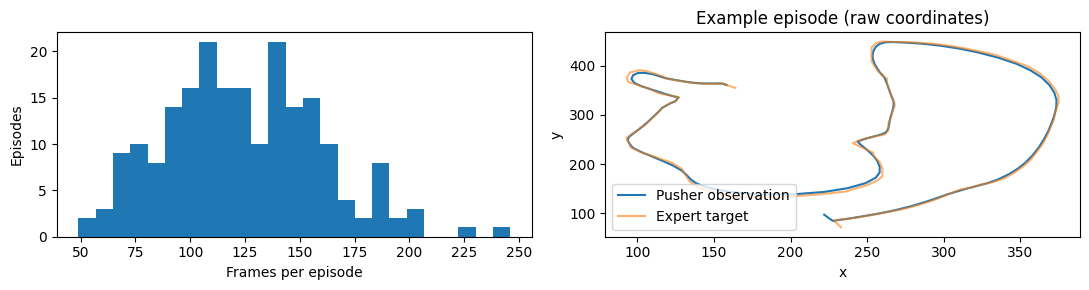

In [17]:
episode_table = df.groupby("episode_index").agg(frames=("frame_index", "size"),
                                               duration_s=("timestamp", "max"))
display(episode_table.describe())
print("Short episodes (< max(k,H)):", int((episode_table.frames < max(K,H)).sum()))
print("Episode lengths:", Counter(episode_table.frames).most_common(5))
fig, ax = plt.subplots(1, 2, figsize=(11, 3))
ax[0].hist(episode_table.frames, bins=25)
ax[0].set(xlabel="Frames per episode", ylabel="Episodes")
first = df.episode_index.eq(df.episode_index.iloc[0]).to_numpy()
ax[1].plot(states[first,0], states[first,1], label="Pusher observation")
ax[1].plot(actions[first,0], actions[first,1], alpha=.6, label="Expert target")
ax[1].set(xlabel="x", ylabel="y", title="Example episode (raw coordinates)")
ax[1].legend()
plt.tight_layout(); plt.show()

### Train, Validation, Test Split
Each outer fold is test once. Within the other four folds, reserve 10% of episodes for validation (rounded up). For 206 episodes, fold 0 has **147 training / 17 validation / 42 test episodes**. No frame-level random split. Reuse the same manifest across architectures, histories, horizons, and seeds; only vary the split seed for an explicitly different partition study.

In [18]:
SPLIT_SEED = 42               # independent of the model/training seed
episode_ids = np.sort(df.episode_index.unique())
outer_folds = np.array_split(np.random.default_rng(SPLIT_SEED).permutation(episode_ids), N_FOLDS)
def split_for_fold(fold):
    test_ids = outer_folds[fold]
    pool = np.concatenate([ids for i, ids in enumerate(outer_folds) if i != fold])
    pool = np.random.default_rng(SPLIT_SEED + 1000 + fold).permutation(pool)
    nval = max(1, int(np.ceil(len(pool) * VAL_FRACTION)))
    return {"train": np.sort(pool[nval:]), "validation": np.sort(pool[:nval]),
            "test": np.sort(test_ids)}

all_splits = [split_for_fold(f) for f in range(N_FOLDS)]
for split in all_splits:
    sets = [set(ids.tolist()) for ids in split.values()]
    assert all(sets[i].isdisjoint(sets[j]) for i in range(3) for j in range(i+1,3))
    assert set.union(*sets) == set(episode_ids.tolist())
assert sorted(np.concatenate([s["test"] for s in all_splits]).tolist()) == episode_ids.tolist()
split_ids = all_splits[FOLD]
frame_split = np.full(len(df), "", dtype=object)
for name, ids in split_ids.items():
    frame_split[np.isin(df.episode_index.to_numpy(), ids)] = name
assert np.all(frame_split != "")

### Print Split Sizes and Save Assignments

In [19]:
display(pd.DataFrame([{"split": n, "episodes": len(ids), "frames": int((frame_split==n).sum())}
                      for n, ids in split_ids.items()]))
manifest = {"repo": REPO_ID, "revision": REVISION, "split_seed": SPLIT_SEED,
            "validation_fraction": VAL_FRACTION,
            "folds": [{n: ids.tolist() for n, ids in s.items()} for s in all_splits]}
manifest_text = json.dumps(manifest, indent=2)
(OUT / "episode_splits.json").write_text(manifest_text)
split_hash = hashlib.sha256(manifest_text.encode()).hexdigest()
df[["index", "episode_index", "frame_index"]].assign(split=frame_split).to_csv(
    OUT / f"frame_assignments_fold{FOLD}.csv", index=False)
print("Manifest SHA256:", split_hash)

,split,episodes,frames
0,train,147,18233
1,validation,17,2147
2,test,42,5270


Manifest SHA256: ddd1e590b47dd913cc3866e733d71ff52be40d306ebc08c2597f2a457ce1926b


### Normalize Inputs and Actions
Use observations ending at t to predict expert actions **a[t:t+H]**, matching the proposal's equation (no off-by-one shift). The first observation repeats when t < k−1. Future targets beyond the episode are zero-padded **after normalization**, with zero loss weight. All three models see the same k observations. Set k=1 for the current-state MLP baseline, and compare models at equal k as well to separate history effects from architecture effects.

Fit statistics on raw training frames only. Do not use the repository's global `meta/stats.json`, which includes held-out episodes. Input features are explicitly whitelisted.

All **18 input coordinates** are normalized independently using training episodes only. Each model sees the same [batch, K, 18] tensor and predicts [batch, H, 2].

In [20]:
train_mask = frame_split == "train"
obs_mean = states[train_mask].mean(0)
obs_std = np.maximum(states[train_mask].std(0), 1e-6)
act_mean = actions[train_mask].mean(0)
act_std = np.maximum(actions[train_mask].std(0), 1e-6)
norm = {"obs_mean": obs_mean, "obs_std": obs_std, "act_mean": act_mean, "act_std": act_std}
np.savez(OUT / f"normalization_fold{FOLD}.npz", **norm)
episodes = {}
for ep, group in df.groupby("episode_index", sort=True):
    idx = group.index.to_numpy()
    episodes[int(ep)] = ((states[idx] - obs_mean) / obs_std, (actions[idx] - act_mean) / act_std)

### Dataset

In [21]:
class EpisodeWindows(Dataset):
    def __init__(self, ids, k, horizon):
        self.k, self.horizon = k, horizon
        self.samples = [(int(ep), t) for ep in ids for t in range(len(episodes[int(ep)][0]))]
    def __len__(self):
        return len(self.samples)
    def __getitem__(self, i):
        ep, t = self.samples[i]
        obs, act = episodes[ep]
        history_idx = np.maximum(np.arange(t-self.k+1, t+1), 0)
        x = obs[history_idx]
        count = min(self.horizon, len(act)-t)
        y = np.zeros((self.horizon, 2), dtype=np.float32)
        valid = np.zeros(self.horizon, dtype=np.float32)
        y[:count] = act[t:t+count]
        valid[:count] = 1
        return torch.from_numpy(x.copy()), torch.from_numpy(y), torch.from_numpy(valid), ep

### Dataloader

In [22]:
datasets = {n: EpisodeWindows(ids, K, H) for n, ids in split_ids.items()}
def make_loader(name, shuffle=False):
    return DataLoader(datasets[name], batch_size=BATCH_SIZE, shuffle=shuffle,
                      num_workers=0, generator=torch.Generator().manual_seed(SEED))
for name, ds in datasets.items():
    assert {ep for ep,t in ds.samples} == set(split_ids[name].tolist())
    x,y,m,ep = ds[0]
    assert x.shape == (K,OBS_DIM) and y.shape == (H,2) and m.shape == (H,)
    assert torch.allclose(x, x[-1:].expand_as(x)) # episode-start history padding
    _,_,last_mask,_ = ds[len(ds)-1]
    assert last_mask.sum().item() == 1
print("Input / target / mask shapes:", x.shape, y.shape, m.shape)

Input / target / mask shapes: torch.Size([4, 18]) torch.Size([1, 2]) torch.Size([1])


## P1 - MLP Policy

### Dataset and Dataloader
Use the shared Q1 datasets and loaders. Do not resplit the data or refit normalization here.

In [23]:
print("Train samples:", len(datasets["train"]))
print("Validation samples:", len(datasets["validation"]))
print("Test samples:", len(datasets["test"]))

Train samples: 18233
Validation samples: 2147
Test samples: 5270


### Network
The MLP flattens the k observations and uses two hidden layers. Set k=1 in the shared settings for the current-state baseline.
For K=4, flattening gives 4 x 18 = 72 inputs, followed by hidden widths 128 and 128, then 2H outputs.

In [24]:
class MLPPolicy(nn.Module):
    def __init__(self, k, horizon, dropout, obs_dim):
        super().__init__()
        self.horizon = horizon
        self.net = nn.Sequential(nn.Flatten(), nn.Linear(k*obs_dim,128), nn.ReLU(), nn.Dropout(dropout),
                                 nn.Linear(128,128), nn.ReLU(), nn.Dropout(dropout),
                                 nn.Linear(128,horizon*2))
    def forward(self, x):
        return self.net(x).reshape(-1,self.horizon,2)

In [25]:
MODEL_TYPES["MLP"] = MLPPolicy
check_network("MLP", MLPPolicy(K,H,DROPOUT,obs_dim=OBS_DIM))

MLP: 26,114 parameters


### Training
Train with Adam and masked MSE. Save and restore the checkpoint with the lowest validation loss; stop early if validation stops improving.

In [30]:
mlp_network = train_policy("MLP", MLPPolicy)

MLP 01: train=0.21567, validation=0.07644
MLP 02: train=0.07333, validation=0.05795
MLP 03: train=0.05502, validation=0.03774
MLP 04: train=0.04053, validation=0.02383
MLP 05: train=0.03144, validation=0.01989
MLP 06: train=0.02709, validation=0.01873
MLP 07: train=0.02547, validation=0.01617
MLP 08: train=0.02429, validation=0.01495
MLP 09: train=0.02340, validation=0.01344
MLP 10: train=0.02195, validation=0.01300
MLP 11: train=0.02177, validation=0.01450
MLP 12: train=0.02209, validation=0.01293
MLP 13: train=0.02111, validation=0.01306
MLP 14: train=0.02103, validation=0.01330
MLP 15: train=0.02107, validation=0.01318


### Plot Training and Validation Loss

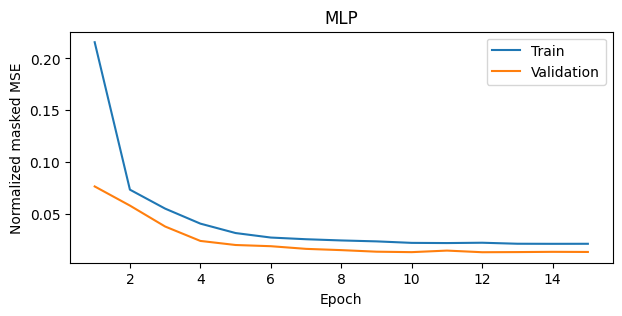

In [31]:
plot_training("MLP")

### Evaluation
Evaluate the restored model on held-out test episodes. Report action-regression MSE, including equal-weight episode MSE. Do not use these scores to choose hyperparameters.

In [32]:
report_test("MLP", mlp_network)

,model,normalized_mse,raw_coordinate_mse,episode_mean_raw_mse
0,MLP,0.016212,160.709717,158.471955


## P2 - LSTM Policy

### Dataset and Dataloader
Use the shared Q1 datasets and loaders. Do not resplit the data or refit normalization here.

In [ ]:
print("Train samples:", len(datasets["train"]))
print("Validation samples:", len(datasets["validation"]))
print("Test samples:", len(datasets["test"]))

### Network
The LSTM reads the observation window in temporal order. Its last hidden output predicts the action chunk; hidden state resets for each window.
The recurrent input_size is 18; both recurrent layers have hidden size 128.

In [ ]:
class LSTMPolicy(nn.Module):
    def __init__(self, k, horizon, dropout, obs_dim):
        super().__init__()
        self.horizon = horizon
        self.rnn = nn.LSTM(obs_dim,128,num_layers=2,batch_first=True,dropout=dropout)
        self.head = nn.Sequential(nn.Dropout(dropout),nn.Linear(128,horizon*2))
    def forward(self, x):
        sequence, _ = self.rnn(x)
        return self.head(sequence[:,-1]).reshape(-1,self.horizon,2)

In [ ]:
MODEL_TYPES["LSTM"] = LSTMPolicy
check_network("LSTM", LSTMPolicy(K,H,DROPOUT,obs_dim=OBS_DIM))

### Training
Train with Adam and masked MSE. Save and restore the checkpoint with the lowest validation loss; stop early if validation stops improving.

In [ ]:
lstm_network = train_policy("LSTM", LSTMPolicy)

### Plot Training and Validation Loss

In [ ]:
plot_training("LSTM")

### Evaluation
Evaluate the restored model on held-out test episodes. Report action-regression MSE, including equal-weight episode MSE. Do not use these scores to choose hyperparameters.

In [ ]:
report_test("LSTM", lstm_network)

## P3 - Transformer Policy

### Dataset and Dataloader
Use the shared Q1 datasets and loaders. Do not resplit the data or refit normalization here.

In [ ]:
print("Train samples:", len(datasets["train"]))
print("Validation samples:", len(datasets["validation"]))
print("Test samples:", len(datasets["test"]))

### Network
The Transformer uses learned position embeddings, two encoder layers, four attention heads, and a causal mask. Its last token predicts the action chunk.
Each 18D observation is projected to a 64D token before adding learned positions.

In [ ]:
class TransformerPolicy(nn.Module):
    def __init__(self, k, horizon, dropout, obs_dim):
        super().__init__()
        self.horizon = horizon
        self.embed = nn.Linear(obs_dim,64)
        self.position = nn.Parameter(torch.zeros(1,k,64))
        nn.init.normal_(self.position, std=.02)
        layer = nn.TransformerEncoderLayer(64,4,dim_feedforward=128,
                                           dropout=dropout,batch_first=True,activation="relu")
        self.encoder = nn.TransformerEncoder(layer, num_layers=2, enable_nested_tensor=False)
        self.head = nn.Linear(64,horizon*2)
    def forward(self, x):
        z = self.embed(x) + self.position[:,:x.size(1)]
        mask = torch.triu(torch.ones(x.size(1),x.size(1),device=x.device,dtype=torch.bool),diagonal=1)
        z = self.encoder(z, mask=mask)
        return self.head(z[:,-1]).reshape(-1,self.horizon,2)

In [ ]:
MODEL_TYPES["Transformer"] = TransformerPolicy
check_network("Transformer", TransformerPolicy(K,H,DROPOUT,obs_dim=OBS_DIM))

### Training
Train with Adam and masked MSE. Save and restore the checkpoint with the lowest validation loss; stop early if validation stops improving.

In [ ]:
transformer_network = train_policy("Transformer", TransformerPolicy)

### Plot Training and Validation Loss

In [ ]:
plot_training("Transformer")

### Evaluation
Evaluate the restored model on held-out test episodes. Report action-regression MSE, including equal-weight episode MSE. Do not use these scores to choose hyperparameters.

In [ ]:
report_test("Transformer", transformer_network)

## COMP - Compare Policies

### Evaluation Summary
Evaluate each restored checkpoint once. Report normalized and original-coordinate MSE, plus equal-weight episode MSE so longer episodes do not dominate every result. A train-mean action predictor provides a simple sanity baseline. Horizon curves below use expert observations and measure **offline action-chunk prediction**, not closed-loop compounding error or simulator success.

In [ ]:
# The normalized zero predictor corresponds to the training-set mean action.
baseline_metrics, baseline_curve = evaluate(None, make_loader("test"))
results = pd.DataFrame([{"model": "Train-mean baseline", **baseline_metrics}] +
                       [{"model": name, **metrics} for name,metrics in test_results.items()])
display(results)
results.to_csv(OUT / f"test_fold{FOLD}_seed{SEED}_k{K}_H{H}_drop{DROPOUT}.csv",index=False)

### Plot Action-Chunk Prediction Error

In [ ]:
for name,curve in {"Train-mean baseline":baseline_curve, **horizon_curves}.items():
    plt.plot(np.arange(H),curve,marker="o",label=name)
plt.xlabel("Action offset from t (0 = current expert action)")
plt.ylabel("Raw-coordinate MSE per valid coordinate")
plt.title("Offline action-chunk error on held-out episodes")
plt.legend()
plt.show()

### Reload a Network and Predict Actions
Supply raw observations up to the current time, with exactly the same 18-value ordering used in training: pusher x/y followed by the 16 block-keypoint values. The checkpoint records this schema and normalization. The helper repeats the first frame for a short history and returns raw 2D action targets. In a later simulator integration, execute the first predicted action and replan; verify the simulator keypoint ordering before use.

In [ ]:
# Load only your own trusted checkpoint.
selected_name = "MLP"  # choose explicitly; do not select architecture using test scores
checkpoint = torch.load(checkpoint_paths[selected_name],map_location="cpu",weights_only=True)
c = checkpoint["config"]
assert c["input_features"] == INPUT_FEATURES and c["obs_dim"] == OBS_DIM
reloaded = MODEL_TYPES[checkpoint["model_type"]](c["k"],c["horizon"],c["dropout"],obs_dim=c["obs_dim"])
reloaded.load_state_dict(checkpoint["model_state"])
reloaded.eval()

In [ ]:
@torch.no_grad()
def predict_chunk(raw_history, model, checkpoint):
    k = checkpoint["config"]["k"]
    history = np.asarray(raw_history,dtype=np.float32)
    assert history.ndim == 2 and history.shape[1] == checkpoint["config"]["obs_dim"] and len(history)>0
    assert np.isfinite(history).all()
    history = history[-k:]
    if len(history)<k:
        history = np.concatenate([np.repeat(history[:1],k-len(history),axis=0),history])
    stats = {key: np.asarray(value,dtype=np.float32) for key,value in checkpoint["normalization"].items()}
    x = torch.from_numpy((history-stats["obs_mean"])/stats["obs_std"]).unsqueeze(0)
    pred = model(x.to(next(model.parameters()).device)).cpu().numpy()[0]
    return pred*stats["act_std"]+stats["act_mean"]

### Save Results

In [ ]:
print("Predicted target chunk:", predict_chunk(states[:1],reloaded,checkpoint))
(OUT / "run_metadata.json").write_text(json.dumps({"config": config, "versions": versions,
    "revision": REVISION, "split_manifest_sha256": split_hash,
    "observation_contract": "pusher (2) + block keypoints (16); no images"},indent=2))
print("Saved outputs:")
for path in sorted(OUT.iterdir()): print(path)
# Optional Colab download (uncomment):
# import shutil
# from google.colab import files
# files.download(shutil.make_archive("pusht_run", "zip", OUT))

## Discussion and Next Experiments
* This revision matches the proposal's observation design: **2 pusher + 16 block-keypoint coordinates**. It uses the official keypoint dataset, not extra features assumed to exist in the video variant.
* The feature order, input dimension, normalization, dataset revision, and episode assignments are saved with checkpoints. Old pusher-only checkpoints are incompatible and must be retrained.
* For full cross-validation, rerun Q1-Q5 for FOLD=0...4, fitting normalization afresh each time. Hold SPLIT_SEED fixed; vary training seeds such as 0,1,2. Compare at equal K/H and training budgets. Set K=1/H=1 for the current-state baseline, then ablate K=2,4,8, H=8, and dropout.
* This notebook still performs **offline** action prediction. Lower test MSE does not establish simulator success. Closed-loop overlap, success over 50 fresh starts, videos, and compounding-error plots require simulator integration and are not claimed here.
* The original pusher-only PDF guide describes the earlier notebook. Use this notebook's 18D architecture descriptions and the new project-update slides for the revised input design.

### Sources
* [LeRobotDataset v3 format documentation](https://huggingface.co/docs/lerobot/lerobot-dataset-v3).
* [Official keypoint dataset, pinned revision](https://huggingface.co/datasets/lerobot/pusht_keypoints/tree/ace8c161a68bc025c21a5f29f85b86a9a2c5e64b).
* [Pinned schema](https://huggingface.co/datasets/lerobot/pusht_keypoints/blob/ace8c161a68bc025c21a5f29f85b86a9a2c5e64b/meta/info.json).
* [PushT simulator observation modes](https://github.com/huggingface/gym-pusht#observation-space).

### Validation
The pinned metadata and all 25,650 parquet rows were inspected. Pusher positions, actions, and episode/frame/global identifiers match the earlier video-variant parquet exactly, so the same episode assignments remain comparable. All three models passed an actual-data end-to-end run at K=4/H=8 with one epoch each, including validation selection, test evaluation, checkpoint save/reload, and episode-boundary checks. Forward/backward checks passed for every proposed K/H pair. A separate MLP run at the delivered default K=4/H=1 completed 10 epochs (fold 0, seed 42); epoch 10 was the best validation checkpoint. Its measured learning curve and offline test results appear in the accompanying project-update deck. These are preliminary single-fold/single-seed results, not a full comparative study. The complete experimental grid and simulator evaluation have not been run.